# PCA vs. Non-negative Matrix Factorization on handwritten digits

**Question.** PCA and non-negative matrix factorization (NMF) both describe a set of images as
combinations of a small number of basis images, but under different constraints. PCA finds an
orthogonal basis capturing as much variance as possible, and its coefficients are free to take
either sign. NMF requires the basis *and* the coefficients to be non-negative, so an image can only
be built by adding pieces together, never by cancelling them out. Those constraints produce very
different bases, and the question here is whether the difference costs anything or buys anything:

> For handwritten digit images, does the additive, parts-based representation learned by NMF retain
> the same class information as the variance-optimal PCA representation, and how do the two sets of
> coefficients differ in interpretability?

**Data.** A balanced subset of MNIST: 100 training images for each of the ten digits (1000 images
total), each a 28x28 grayscale image flattened to a 784-dimensional vector with pixel values in
[0, 255], plus a small held-out test set drawn from the MNIST test split.

**Approach.**

1. Compute the PCA basis by SVD of the mean-centred data and view the leading principal directions
   as images.
2. Classify the test images by nearest neighbour in a low-dimensional PCA subspace. This is the
   reference point everything else is measured against.
3. Fit NMF, $X \approx WH$ with $W, H \ge 0$, for several values of the rank $r$ using multiplicative
   updates, and inspect the learned components.
4. Infer non-negative coefficients for the test images against the *fixed* learned basis, and repeat
   the nearest-neighbour classification in NMF coefficient space.
5. For one image per digit, compare the PCA and NMF coefficient vectors directly.

**The objective.** Pixel intensities are non-negative amounts of ink, so rather than squared error
we maximize the Poisson log-likelihood of the factorization,

$$
L(W, H) \;=\; \sum_{i,j} \Big[ x_{ij} \log (WH)_{ij} - (WH)_{ij} \Big],
$$

which is monotonically increased by the Lee & Seung (2001) multiplicative updates

$$
w_{ik} \leftarrow w_{ik} \,\frac{\sum_j h_{kj}\, x_{ij} / (WH)_{ij}}{\sum_j h_{kj}},
\qquad
h_{kj} \leftarrow h_{kj} \,\frac{\sum_i w_{ik}\, x_{ij} / (WH)_{ij}}{\sum_i w_{ik}}.
$$

Each factor is a ratio of positive quantities, so non-negativity is preserved automatically and
there is no projection step. Both factorizations are written out directly below rather than taken
from scikit-learn, so the updates are visible.

**Running this.** The only external file needed is `mnist_all.mat`. In Colab, upload it to
`/content` (the default working directory) and run the notebook top to bottom; everything else is
self-contained. Requires NumPy, SciPy and Matplotlib.

## Setup and data

`mnist_all.mat` stores the full MNIST split as 20 arrays, `train0`...`train9` and
`test0`...`test9`, one per digit. The loader shuffles each digit's images under a fixed seed and
keeps the first 100 per class for training, then draws a handful of test images at random. Seeding
is deliberate: it keeps every figure in this notebook reproducible from run to run.

In [ ]:
import os

import numpy as np
import scipy.io
import matplotlib.pyplot as plt

DATAFILE = "mnist_all.mat"
IMG_SHAPE = (28, 28)
N_PER_DIGIT = 100   # training images kept per digit class
N_TEST = 5          # held-out images to classify

if not os.path.exists(DATAFILE):
    raise FileNotFoundError(
        "Could not find '%s' in %s.\n"
        "Upload the file to the working directory (in Colab that is /content) and re-run."
        % (DATAFILE, os.getcwd())
    )

In [ ]:
def load_mnist(path, n_train=N_PER_DIGIT, n_test=N_TEST, seed_shuffle=777, seed_test=200):
    """Load a balanced MNIST subset from the .mat file.

    Returns (train, test_images, test_labels) where train is a list of ten
    (n_train, 784) arrays indexed by digit, test_images is (n_test, 784), and
    test_labels is the list of true digits for those images.
    """
    raw = scipy.io.loadmat(path)

    # Shuffle within each class so the kept subset is not just the first images on file
    rng = np.random.RandomState(seed_shuffle)
    train, test_pool = [], []
    for digit in range(10):
        tr = raw["train%d" % digit].copy()
        rng.shuffle(tr)
        train.append(tr[:n_train, :])

        te = raw["test%d" % digit].copy()
        rng.shuffle(te)
        test_pool.append(te)

    # Draw the held-out images: a random class, then a random image from it
    rng = np.random.RandomState(seed_test)
    test_images, test_labels = [], []
    for _ in range(n_test):
        digit = rng.randint(0, 10)
        pool = test_pool[digit]
        test_images.append(pool[rng.randint(0, pool.shape[0]), :])
        test_labels.append(digit)

    return train, np.stack(test_images), test_labels


train, test_images, test_labels = load_mnist(DATAFILE)

# Non-negative design matrix, classes stacked in order 0..9. Row k*N_PER_DIGIT + i
# is image i of digit k, which is what lets us recover a label from a row index.
X = np.asarray(train, dtype=float).reshape(-1, IMG_SHAPE[0] * IMG_SHAPE[1])
X_test = np.asarray(test_images, dtype=float)

# Mean-centred copy, used only by PCA
pixel_mean = X.mean(axis=0)
Xc = X - pixel_mean

print("training matrix: %s, pixel range [%.0f, %.0f]" % (X.shape, X.min(), X.max()))
print("test matrix:     %s" % (X_test.shape,))
print("test labels:     %s" % test_labels)

training matrix: (1000, 784), pixel range [0, 255]
test matrix:     (5, 784)
test labels:     [9, 4, 7, 9, 9]


A small helper for displaying 784-dimensional vectors as images, used throughout.

In [ ]:
def grid_columns(n, max_col=5):
    """Column count that fills a grid of n panels, as wide as possible up to max_col."""
    divisors = [c for c in range(2, max_col + 1) if n % c == 0]
    return max(divisors) if divisors else min(n, max_col)


def show_grid(images, title, n_col=None, shape=IMG_SHAPE, row_labels=None, col_labels=None):
    """Display a list of flattened images in a grid, one image per panel."""
    images = list(images)
    n_col = n_col or grid_columns(len(images))
    n_row = int(np.ceil(len(images) / n_col))
    fig, axes = plt.subplots(n_row, n_col,
                             figsize=(1.9 * n_col, 2.1 * n_row),
                             squeeze=False)

    for ax, img in zip(axes.ravel(), images):
        ax.imshow(np.asarray(img).reshape(shape), cmap="gray_r", interpolation="nearest")
    for ax in axes.ravel()[len(images):]:
        ax.set_visible(False)   # hide leftover panels when the grid is not full
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])

    if row_labels is not None:
        for ax, label in zip(axes[:, 0], row_labels):
            ax.set_ylabel(label, size="large")
    if col_labels is not None:
        for ax, label in zip(axes[0], col_labels):
            ax.set_title(label)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## 1. The PCA basis

The principal directions are the right singular vectors of the centred data matrix. Reshaped to
28x28 they are images themselves, so we can look at them directly.

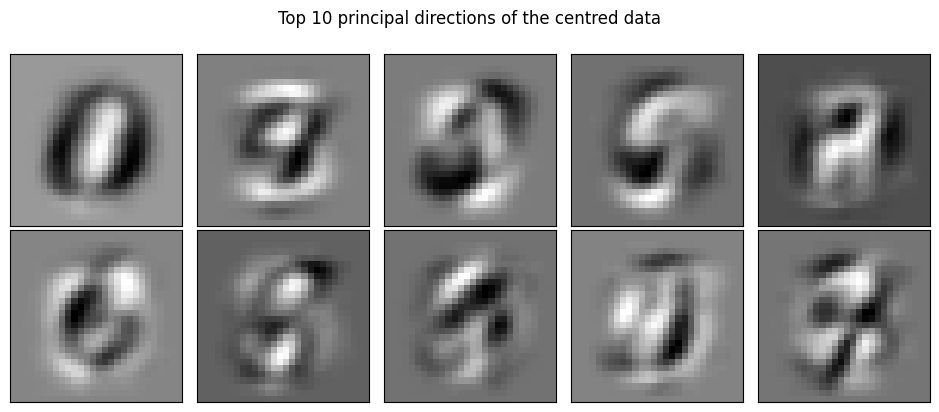

first  3 components explain  23.6% of the variance
first  6 components explain  37.7% of the variance
first  8 components explain  44.0% of the variance
first 10 components explain  49.2% of the variance


In [ ]:
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)

show_grid([Vt[i, :] for i in range(10)],
          "Top 10 principal directions of the centred data")

var_explained = np.cumsum(s ** 2) / np.sum(s ** 2)
for k in [3, 6, 8, 10]:
    print("first %2d components explain %5.1f%% of the variance" % (k, 100 * var_explained[k - 1]))

The leading directions are not localized strokes. Each has both bright and dark regions, because a
principal direction is free to subtract ink as well as add it, and each mixes several digit shapes
at once. Looking at one in isolation says little. This is exactly the behaviour the non-negativity
constraint is meant to change.

## 2. Nearest-neighbour baseline in a PCA subspace

The baseline keeps the first $k$ principal directions, projects every image onto that subspace, and
labels each test image with the class of its nearest training image. Since the rows of $V$ are
orthonormal, distances between projections equal distances between the $k$-dimensional coordinate
vectors, so comparing coordinates is enough.

In [ ]:
def pca_coords(images, basis):
    """Coordinates of each row of `images` in the subspace spanned by `basis` (orthonormal rows)."""
    return np.atleast_2d(images) @ basis.T


def nearest_row(train_coords, query):
    """Row index of the training point closest to `query` in Euclidean distance."""
    return int(np.argmin(np.linalg.norm(train_coords - query, axis=1)))


def row_to_label(row_idx, n_per_digit=N_PER_DIGIT):
    """Recover (digit, within-class index) from a row index of the stacked data matrix."""
    return row_idx // n_per_digit, row_idx % n_per_digit


def classify(train_coords, test_coords):
    """Nearest-neighbour label and matched training image for every row of `test_coords`."""
    predictions, matches = [], []
    for query in test_coords:
        digit, idx = row_to_label(nearest_row(train_coords, query))
        predictions.append(digit)
        matches.append(train[digit][idx, :])
    return predictions, matches


def accuracy(predictions, labels):
    return sum(p == t for p, t in zip(predictions, labels)) / len(labels)


K_PCA = 8
V_pca = Vt[:K_PCA, :]

pca_pred, pca_matches = classify(pca_coords(X, V_pca), pca_coords(X_test, V_pca))
pca_acc = accuracy(pca_pred, test_labels)

print("PCA, k = %d" % K_PCA)
print("  true:      %s" % test_labels)
print("  predicted: %s" % pca_pred)
print("  accuracy:  %d/%d" % (pca_acc * len(test_labels), len(test_labels)))

PCA, k = 8
  true:      [9, 4, 7, 9, 9]
  predicted: [9, 4, 7, 9, 9]
  accuracy:  5/5


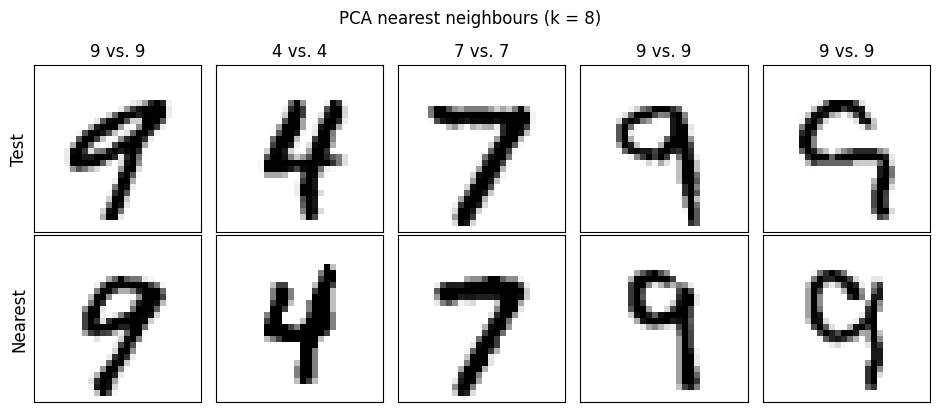

In [ ]:
def show_matches(matches, predictions, title):
    """Test images on the top row, their nearest training images directly below."""
    show_grid(list(X_test) + list(matches), title,
              n_col=len(test_labels),
              row_labels=["Test", "Nearest"],
              col_labels=["%d vs. %d" % (t, p) for t, p in zip(test_labels, predictions)])


show_matches(pca_matches, pca_pred, "PCA nearest neighbours (k = %d)" % K_PCA)

## 3. Fitting NMF

`nmf_fit` runs the multiplicative updates on the raw, uncentred data, which is non-negative as
required. The `eps` in every denominator guards against division by zero, which matters here because
MNIST images are exactly zero over most of the border. $W$ is updated first and $WH$ is recomputed
before updating $H$, so each factor is updated against the current value of the other.

In [ ]:
def nmf_fit(X, r, num_iters=200, seed=0, eps=1e-10):
    """Factorize X ~ W H with W, H >= 0 under the Poisson log-likelihood.

    Lee & Seung multiplicative updates. Returns (W, H) of shapes (n, r) and (r, p).
    """
    rng = np.random.RandomState(seed)
    W = rng.rand(X.shape[0], r)
    H = rng.rand(r, X.shape[1])
    ones = np.ones_like(X)

    for _ in range(num_iters):
        W *= ((X / (W @ H + eps)) @ H.T) / (ones @ H.T + eps)
        H *= (W.T @ (X / (W @ H + eps))) / (W.T @ ones + eps)

    return W, H


def poisson_loglik(X, W, H, eps=1e-10):
    """Value of the objective, used to check that the updates are improving the fit."""
    WH = W @ H + eps
    return float(np.sum(X * np.log(WH) - WH))


R_VALUES = [3, 6, 10]

nmf_models = {}
for r in R_VALUES:
    W, H = nmf_fit(X, r=r)
    nmf_models[r] = (W, H)
    print("r = %2d   W %s   H %s   log-likelihood %.4e"
          % (r, W.shape, H.shape, poisson_loglik(X, W, H)))

r =  3   W (1000, 3)   H (3, 784)   log-likelihood 9.4480e+07
r =  6   W (1000, 6)   H (6, 784)   log-likelihood 9.7796e+07
r = 10   W (1000, 10)   H (10, 784)   log-likelihood 1.0017e+08


The updates are only useful if they actually climb the objective, so before reading anything into
the components, check that the log-likelihood increases monotonically and has largely levelled off
by the iteration count used above.

monotonically increasing: True
gain over last 50 iterations: 0.497% of total gain


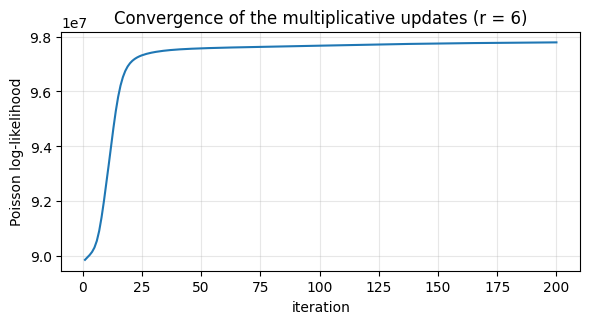

In [ ]:
r_check, eps = 6, 1e-10
rng = np.random.RandomState(0)
W_chk = rng.rand(X.shape[0], r_check)
H_chk = rng.rand(r_check, X.shape[1])
ones = np.ones_like(X)

history = []
for it in range(1, 201):
    W_chk *= ((X / (W_chk @ H_chk + eps)) @ H_chk.T) / (ones @ H_chk.T + eps)
    H_chk *= (W_chk.T @ (X / (W_chk @ H_chk + eps))) / (W_chk.T @ ones + eps)
    history.append(poisson_loglik(X, W_chk, H_chk))

print("monotonically increasing:", bool(np.all(np.diff(history) >= 0)))
print("gain over last 50 iterations: %.3f%% of total gain"
      % (100 * (history[-1] - history[-51]) / (history[-1] - history[0])))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(history) + 1), history)
plt.xlabel("iteration")
plt.ylabel("Poisson log-likelihood")
plt.title("Convergence of the multiplicative updates (r = %d)" % r_check)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

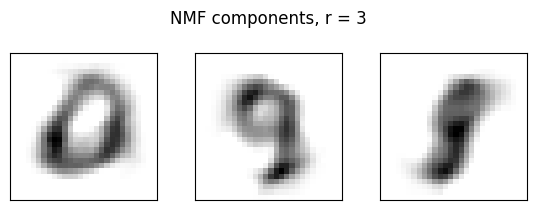

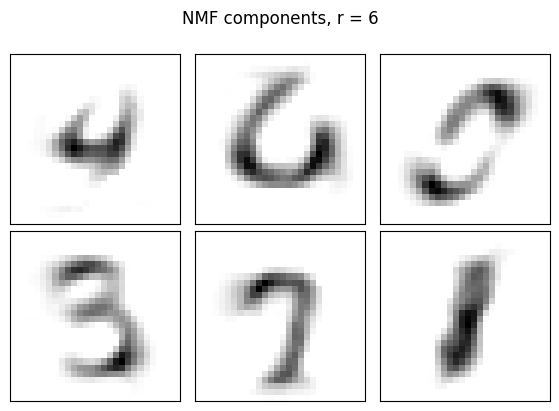

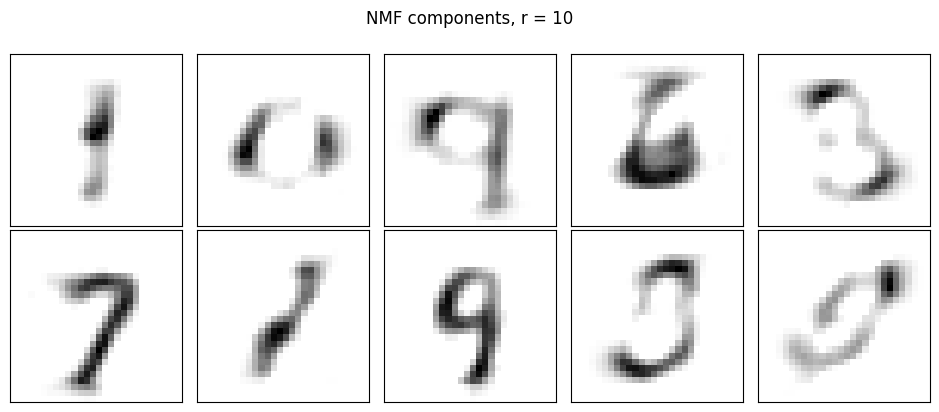

In [ ]:
# The rows of H are the learned basis images
for r in R_VALUES:
    _, H = nmf_models[r]
    show_grid([H[i, :] for i in range(r)],
              "NMF components, r = %d" % r)

At $r = 3$ each component has to account for several digits at once and comes out as a blur. As $r$
grows the components sharpen into strokes, loops and partial digits, and some are recognisable as
single digit shapes. Unlike the principal directions they are everywhere non-negative, so each one is
ink that gets added rather than a contrast between two regions.

## 4. Nearest neighbour in NMF coefficient space

For training images the coefficients are already available as the rows of $W$. A test image has to be
projected onto the basis learned from the training set, which means holding $H$ fixed and running
only the $W$ update until the coefficients settle. This is the proper analogue of a PCA projection:
the basis is not allowed to adapt to the test image.

In [ ]:
def nmf_transform(images, H, num_iters=200, seed=0, eps=1e-10):
    """Non-negative coefficients of `images` against a fixed basis H (H is not modified)."""
    images = np.atleast_2d(images)
    rng = np.random.RandomState(seed)
    coeffs = rng.rand(images.shape[0], H.shape[0])
    ones = np.ones_like(images)

    for _ in range(num_iters):
        coeffs *= ((images / (coeffs @ H + eps)) @ H.T) / (ones @ H.T + eps)

    return coeffs


nmf_pred, nmf_acc, nmf_matches = {}, {}, {}

for r in R_VALUES:
    W, H = nmf_models[r]
    preds, matches = classify(W, nmf_transform(X_test, H))
    nmf_pred[r], nmf_matches[r] = preds, matches
    nmf_acc[r] = accuracy(preds, test_labels)

print("true labels: %s\n" % test_labels)
print("%-18s %-20s %s" % ("representation", "predicted", "accuracy"))
print("%-18s %-20s %d/%d" % ("PCA, k = %d" % K_PCA, pca_pred,
                             pca_acc * len(test_labels), len(test_labels)))
for r in R_VALUES:
    print("%-18s %-20s %d/%d" % ("NMF, r = %d" % r, nmf_pred[r],
                                 nmf_acc[r] * len(test_labels), len(test_labels)))

true labels: [9, 4, 7, 9, 9]

representation     predicted            accuracy
PCA, k = 8         [9, 4, 7, 9, 9]      5/5
NMF, r = 3         [8, 2, 7, 9, 9]      3/5
NMF, r = 6         [9, 4, 7, 9, 5]      4/5
NMF, r = 10        [9, 9, 7, 9, 9]      4/5


To pick a rank to look at in detail, take the smallest $r$ that reaches the best accuracy observed:
among representations that classify equally well, the lowest-dimensional one is preferable.

best NMF accuracy 4/5, reached at r = [6, 10]; smallest such r = 6


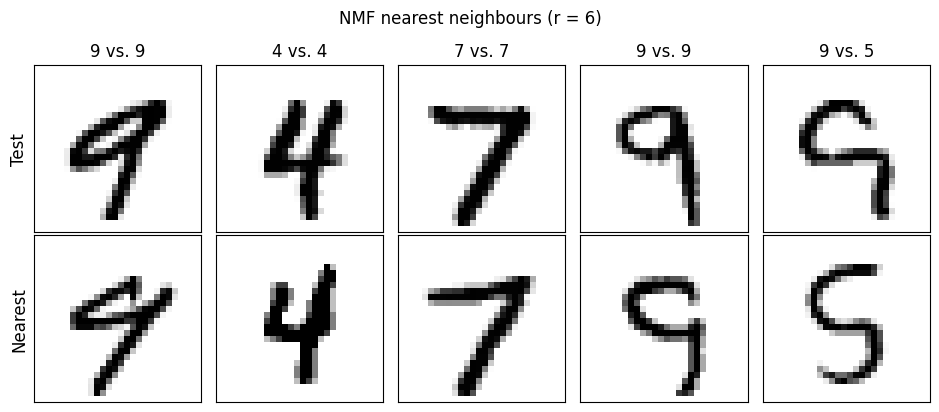

In [ ]:
best_acc = max(nmf_acc.values())
R_BEST = min(r for r in R_VALUES if nmf_acc[r] == best_acc)

print("best NMF accuracy %d/%d, reached at r = %s; smallest such r = %d"
      % (best_acc * len(test_labels), len(test_labels),
         [r for r in R_VALUES if nmf_acc[r] == best_acc], R_BEST))

show_matches(nmf_matches[R_BEST], nmf_pred[R_BEST],
             "NMF nearest neighbours (r = %d)" % R_BEST)

## 5. Comparing the coefficients directly

Accuracy indicates whether the two representations carry comparable class information; it says
nothing about what the numbers themselves look like. For that, take one randomly chosen training
image per digit and compare its PCA coefficients with its NMF coefficients, using the $r = 10$ model
and the first 10 principal directions so both representations have the same dimension.

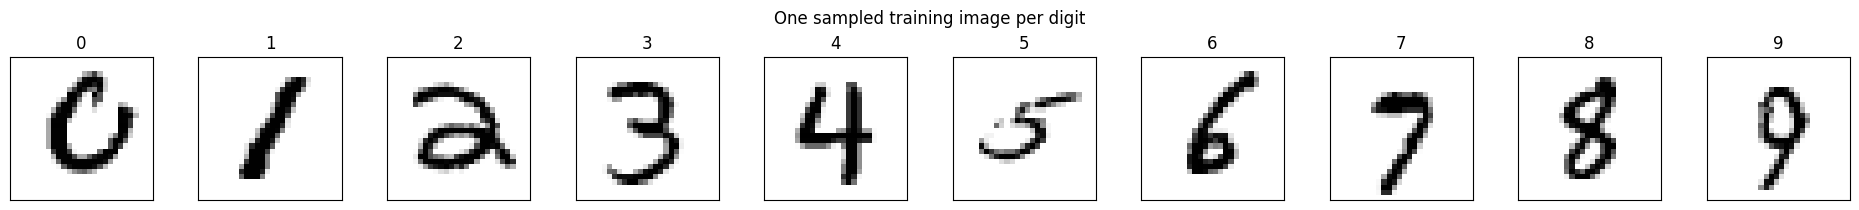

PCA: range [  -883.3,    974.5]   negative  50/100   near zero    8%
NMF: range [     0.0,     55.5]   negative   0/100   near zero   65%


In [ ]:
N_COMP = 10

rng = np.random.RandomState(1)
sample_idx = [rng.randint(0, train[d].shape[0]) for d in range(10)]
samples = np.asarray([train[d][i, :] for d, i in enumerate(sample_idx)], dtype=float)

show_grid(samples, "One sampled training image per digit",
          n_col=10, col_labels=[str(d) for d in range(10)])

# PCA: centre with the training mean, then project onto the leading directions
pca_c = (samples - pixel_mean) @ Vt[:N_COMP, :].T

# NMF: infer non-negative coefficients against the r = 10 basis
_, H_cmp = nmf_models[N_COMP]
nmf_c = nmf_transform(samples, H_cmp)

for name, c in [("PCA", pca_c), ("NMF", nmf_c)]:
    near_zero = np.mean(np.abs(c) < 0.05 * np.abs(c).max())
    print("%s: range [%8.1f, %8.1f]   negative %3d/%d   near zero %4.0f%%"
          % (name, c.min(), c.max(), (c < 0).sum(), c.size, 100 * near_zero))

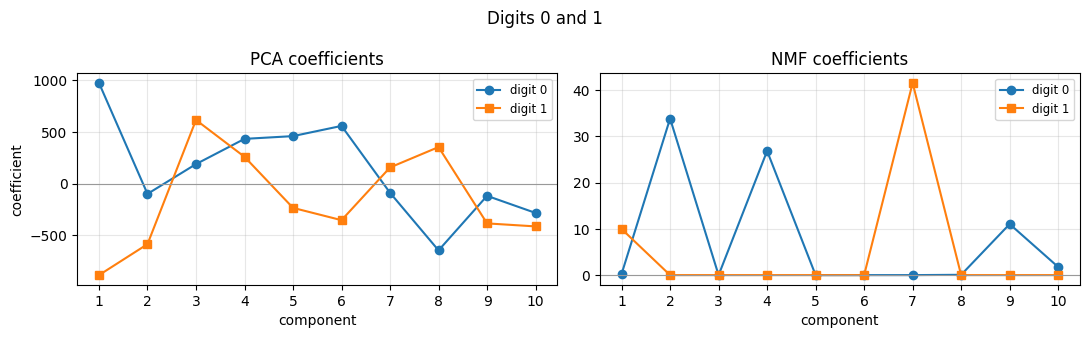

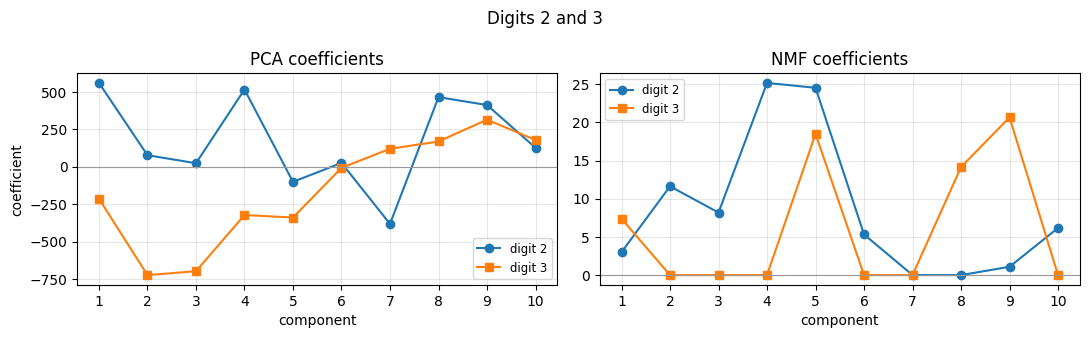

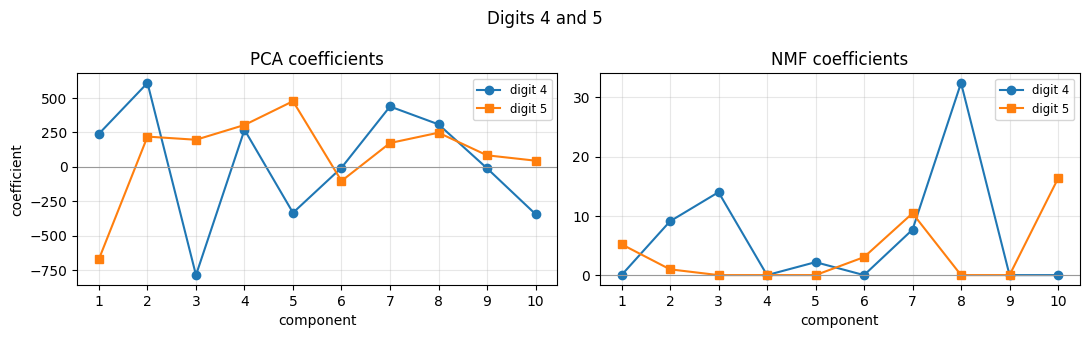

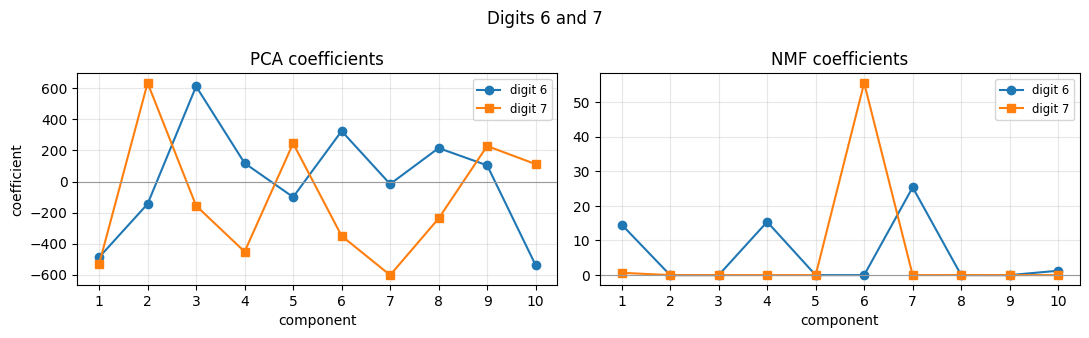

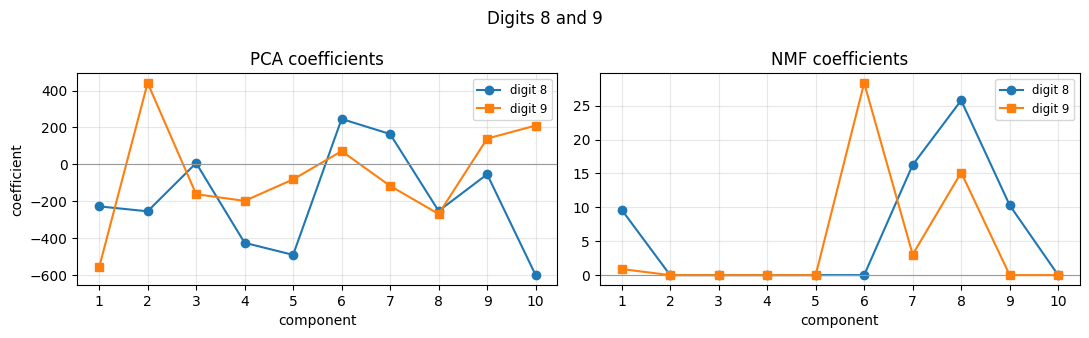

In [ ]:
components = np.arange(1, N_COMP + 1)

for d1, d2 in [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

    for ax, coeffs, name in zip(axes, [pca_c, nmf_c], ["PCA", "NMF"]):
        ax.plot(components, coeffs[d1], marker="o", label="digit %d" % d1)
        ax.plot(components, coeffs[d2], marker="s", label="digit %d" % d2)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title("%s coefficients" % name)
        ax.set_xlabel("component")
        ax.set_xticks(components)
        ax.grid(alpha=0.3)
        ax.legend(fontsize="small")

    axes[0].set_ylabel("coefficient")
    fig.suptitle("Digits %d and %d" % (d1, d2))
    fig.tight_layout()
    plt.show()

## What the comparison shows

**Classification.** Nearest neighbour in the NMF coefficient space is close to the PCA subspace
baseline once $r$ is large enough to give each digit class something to work with, and it reaches
that level in fewer dimensions than the PCA baseline uses. The weaker result at $r = 3$ is a budget
problem rather than evidence against the method, since three additive parts cannot span ten digit
shapes. Non-negativity therefore does not destroy the class information, which is the first thing
to worry about when constraining a factorization this heavily. It does not obviously improve
accuracy either: on a test set this small the sensible reading is that the two representations are
comparable, not that one wins.

**Basis.** The two bases are qualitatively different in a way the figures make obvious. Principal
directions are signed and global: each is a contrast pattern mixing several digits, and an
individual one is not interpretable on its own. NMF components are non-negative and local: strokes,
loops and partial digits that get summed to form an image. That follows directly from the
constraint. With no negative coefficients available, the model cannot express a shape as "this blob
minus that blob" and is pushed toward pieces that actually occur in the data.

**Coefficients.** PCA coefficients straddle zero, with roughly half negative, so a coefficient's
sign indicates which side of a contrast an image falls on rather than how much of anything it
contains. NMF coefficients are non-negative by construction and noticeably sparser: for a given
digit a few components are clearly active and the rest sit near zero, and which ones are active
varies by class. That makes a single NMF coefficient readable as the amount of a particular stroke
pattern present in the image, which is the practical payoff of the additive representation and the
reason NMF is often preferred when the factors themselves have to be explained.

**Caveats.** The held-out set here is deliberately small, so the accuracy figures separate the two
representations only coarsely; a larger test set would be needed to claim a real difference rather
than a comparable one. The multiplicative updates maximize a non-convex objective and converge to a
local optimum, so both the basis and the coefficients depend on the random initialization. Every fit
above is seeded for that reason, and a fuller study would repeat each fit from several
initializations and report the spread.